# 00 · EDA — Adult (Census Income)

**Problema:** Queremos predecir si una persona gana más de 50.000 dólares al año teniendo en cuenta sus características personales y laborales, como la edad, los estudios, la ocupación o las horas trabajadas.

**Dataset:** Utilizaremos el dataset [Adult de UCI](https://archive.ics.uci.edu/dataset/2/adult), basado en el censo de Estados Unidos de 1994 y publicado por Becker y Kohavi (1996).

**Tipo de problema:** Aprendizaje supervisado de clasificación binaria, donde distinguiremos entre personas que ganan 50.000 dólares o menos (`<=50K`, clase 0) y personas que ganan más de 50.000 dólares (`>50K`, clase 1).

## 0. Librerías y configuración

In [1]:
# Si no tienes alguna librería, quita el # de la línea siguiente y ejecútala una vez:
# %pip install pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Carga de datos

Primero cargamos el fichero para ver cómo vienen los datos.

In [2]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
df_bruto = pd.read_csv(url)
df_bruto.head(10)

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
3,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
4,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
5,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
6,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
7,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
8,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K
9,37,Private,280464,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,80,United-States,>50K


El fichero no tiene cabecera, por lo que pandas ha usado la primera persona como nombres de columna.

Además, según la documentación de UCI, los textos llevan un espacio delante y los datos que faltan vienen como `?`.

In [3]:
columnas = ['edad', 'tipo_empleo', 'peso_censo', 'educacion', 'educacion_num',
            'estado_civil', 'ocupacion', 'relacion', 'raza', 'sexo',
            'ganancia_capital', 'perdida_capital', 'horas_semana', 'pais_origen',
            'ingresos']

df = pd.read_csv(url, header=None, names=columnas,
                 skipinitialspace=True, na_values='?')
df.head()

,edad,tipo_empleo,peso_censo,educacion,educacion_num,estado_civil,ocupacion,relacion,raza,sexo,ganancia_capital,perdida_capital,horas_semana,pais_origen,ingresos
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Tipos de variables


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   edad              32561 non-null  int64
 1   tipo_empleo       30725 non-null  str  
 2   peso_censo        32561 non-null  int64
 3   educacion         32561 non-null  str  
 4   educacion_num     32561 non-null  int64
 5   estado_civil      32561 non-null  str  
 6   ocupacion         30718 non-null  str  
 7   relacion          32561 non-null  str  
 8   raza              32561 non-null  str  
 9   sexo              32561 non-null  str  
 10  ganancia_capital  32561 non-null  int64
 11  perdida_capital   32561 non-null  int64
 12  horas_semana      32561 non-null  int64
 13  pais_origen       31978 non-null  str  
 14  ingresos          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


- Hay 32.561 filas y 15 columnas.
- 6 variables numéricas (`edad`, `peso_censo`, `educacion_num`, `ganancia_capital`, `perdida_capital`, `horas_semana`) y 9 de texto (las categóricas más el target `ingresos`).
- Los tipos son correctos.
- `tipo_empleo`, `ocupacion` y `pais_origen` tienen nulos, ya que tienen menos de 32.561 valores.


In [5]:
df.nunique().sort_values()


sexo                    2
ingresos                2
raza                    5
relacion                6
estado_civil            7
tipo_empleo             8
ocupacion              14
educacion              16
educacion_num          16
pais_origen            41
edad                   73
perdida_capital        92
horas_semana           94
ganancia_capital      119
peso_censo          21648
dtype: int64

- `sexo` e `ingresos` solo tienen dos valores.
- La mayoría de categóricas tienen pocas categorías, salvo `pais_origen` con 41, que agruparemos más adelante.
- `educacion` y `educacion_num` tienen 16 valores cada una, parece que dicen lo mismo.
- `peso_censo` es un peso que usa el censo para sus cálculos, no una característica de la persona, así que lo quitamos.

In [6]:
df.groupby('educacion')['educacion_num'].unique().sort_values()

educacion
Preschool        [1]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
10th             [6]
11th             [7]
12th             [8]
HS-grad          [9]
Some-college    [10]
Assoc-voc       [11]
Assoc-acdm      [12]
Bachelors       [13]
Masters         [14]
Prof-school     [15]
Doctorate       [16]
Name: educacion_num, dtype: object

Cada nivel de estudios tiene siempre el mismo número, del 1 al 16. Son la misma información, así que nos quedamos con `educacion_num`.

In [7]:
df = df.drop(columns=['educacion', 'peso_censo'])
df.shape

(32561, 13)

## 3. Variable objetivo

Lo que queremos predecir es `ingresos`, que solo tiene dos valores: si la persona gana más de 50.000 dólares al año o 50.000 dólares o menos. Primero vemos cuántas personas hay en cada grupo.

In [8]:
df['ingresos'].value_counts()

ingresos
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [9]:
df['ingresos'].value_counts(normalize=True)

ingresos
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64

Hay unas 24.700 personas que ganan 50K o menos (76 %) y unas 7.800 que ganan más (24 %). Es decir, por cada persona que gana más de 50K hay tres que no.

Pasamos el target a números (1 = más de 50K, 0 = 50K o menos) porque el modelo necesita números, y lo vemos en un gráfico:

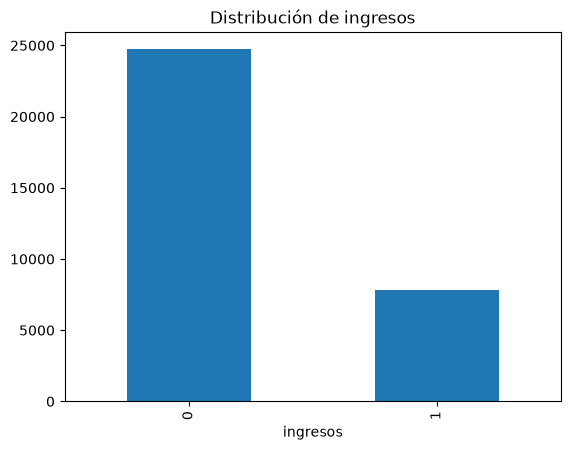

In [10]:
df['ingresos'] = (df['ingresos'] == '>50K').astype(int)
df['ingresos'].value_counts().plot(kind='bar', title='Distribución de ingresos')
plt.show()

## 4. Registros duplicados

Miramos si hay filas repetidas.

In [11]:
df.duplicated().sum()

np.int64(3465)

Salen 3.465 filas repetidas, que son muchas. Puede que quitar `peso_censo` haya hecho que personas distintas parezcan iguales. Vamos a comprobarlo con el fichero original:

In [12]:
pd.read_csv(url, header=None).duplicated().sum()

np.int64(24)

En el original solo hay 24 copias exactas. Efectivamente al quitar `peso_censo`, las personas parecen iguales. Vemos qué perfiles se repiten más:

In [13]:
df.value_counts().head(5)

edad  tipo_empleo  educacion_num  estado_civil        ocupacion     relacion  raza   sexo  ganancia_capital  perdida_capital  horas_semana  pais_origen    ingresos
33    Private      9              Married-civ-spouse  Craft-repair  Husband   White  Male  0                 0                40            United-States  0           16
35    Private      9              Married-civ-spouse  Craft-repair  Husband   White  Male  0                 0                40            United-States  0           15
51    Private      9              Married-civ-spouse  Craft-repair  Husband   White  Male  0                 0                40            United-States  0           14
39    Private      9              Married-civ-spouse  Craft-repair  Husband   White  Male  0                 0                40            United-States  0           14
37    Private      9              Married-civ-spouse  Craft-repair  Husband   White  Male  0                 0                40            United-States  0

El número de la derecha es cuántas personas tienen ese perfil exacto. Son perfiles muy comunes (hombres casados con bachillerato que trabajan 40 horas en la privada), así que es normal que se repitan. Son personas reales, no errores, por lo que no las borraremos.

Las 24 copias exactas del fichero original sí serían errores, pero son solo un 0,07 % de los datos y no cambian nada, así que también las dejamos.

## 5. Valores faltantes y erróneos

Vemos cuántos datos faltan en cada columna.

In [14]:
df.isna().sum()

edad                   0
tipo_empleo         1836
educacion_num          0
estado_civil           0
ocupacion           1843
relacion               0
raza                   0
sexo                   0
ganancia_capital       0
perdida_capital        0
horas_semana           0
pais_origen          583
ingresos               0
dtype: int64

Faltan datos en `tipo_empleo` y `ocupacion` (unos 1.840 en cada una) y en `pais_origen` (583). El resto de columnas están completas.

Antes de rellenarlos, nos preguntamos si a la gente sin ocupación registrada le va igual que al resto:

In [15]:
df.groupby(df['ocupacion'].isna())['ingresos'].mean()

ocupacion
False    0.249040
True     0.103635
Name: ingresos, dtype: float64

Solo un 10 % de las personas sin ocupación registrada gana más de 50K, frente al 25 % del resto. Si les asignamos la ocupación más común, estaríamos suponiendo que trabajan en lo mismo que los demás, y eso no sería correcto. Por eso las dejamos como Desconocido.

Podrían ser estudiantes, jubilados o personas en paro, pero no podemos saberlo con estos datos.

Ahora comprobamos si a `tipo_empleo` también le faltan datos en esas mismas personas.

In [16]:
(df['tipo_empleo'].isna() & df['ocupacion'].isna()).sum()

np.int64(1836)

Sale 1.836, justo todos los vacíos de `tipo_empleo`. Es el mismo grupo de gente, así que también le ponemos `Desconocido`.

Por último, miramos `pais_origen`:

In [17]:
df.groupby(df['pais_origen'].isna())['ingresos'].mean()

pais_origen
False    0.240634
True     0.250429
Name: ingresos, dtype: float64

Aquí no hay diferencia (24 % y 25 %), así que daría igual cómo rellenarlo. Usamos `Desconocido` también, para hacerlo igual en las tres.

In [18]:
df = df.fillna('Desconocido')
df.isna().sum().sum()

np.int64(0)

Ya no queda ningún dato vacío.

Ahora miramos si hay valores erróneos. Para eso vemos el mínimo y el máximo de cada variable numérica:

In [19]:
df.describe().loc[['min', 'max']]

,edad,educacion_num,ganancia_capital,perdida_capital,horas_semana,ingresos
min,17.0,1.0,0.0,0.0,1.0,0.0
max,90.0,16.0,99999.0,4356.0,99.0,1.0


Todo tiene sentido: edades entre 17 y 90, horas entre 1 y 99 (una semana tiene 168) y ninguna ganancia ni pérdida negativa. No hay valores erróneos en los números.

Ahora miramos los valores de las variables de texto, para ver si hay alguno mal escrito:

In [20]:
for col in ['tipo_empleo', 'estado_civil', 'ocupacion', 'relacion', 'raza', 'sexo', 'pais_origen']:
    print(col, ':', df[col].unique())
    print()

tipo_empleo : <ArrowStringArray>
[       'State-gov', 'Self-emp-not-inc',          'Private',
      'Federal-gov',        'Local-gov',      'Desconocido',
     'Self-emp-inc',      'Without-pay',     'Never-worked']
Length: 9, dtype: str

estado_civil : <ArrowStringArray>
[        'Never-married',    'Married-civ-spouse',              'Divorced',
 'Married-spouse-absent',             'Separated',     'Married-AF-spouse',
               'Widowed']
Length: 7, dtype: str

ocupacion : <ArrowStringArray>
[     'Adm-clerical',   'Exec-managerial', 'Handlers-cleaners',
    'Prof-specialty',     'Other-service',             'Sales',
      'Craft-repair',  'Transport-moving',   'Farming-fishing',
 'Machine-op-inspct',      'Tech-support',       'Desconocido',
   'Protective-serv',      'Armed-Forces',   'Priv-house-serv']
Length: 15, dtype: str

relacion : <ArrowStringArray>
['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
 'Other-relative']
Length: 6, dtype: str

raza : <ArrowStr

Casi todo está bien escrito, pero en `pais_origen` hay algunos países mal escritos o cortados (`Columbia` en vez de Colombia, `Trinadad&Tobago`, `Hong` en vez de Hong Kong) y uno poco claro (`South`). No es grave, porque más adelante agrupamos todos los países que no son Estados Unidos en `Otro`.

## 6. Variables numéricas

Separamos las columnas numéricas para analizarlas juntas.

In [21]:
numericas = ['edad', 'educacion_num', 'horas_semana', 'ganancia_capital', 'perdida_capital']
df[numericas].describe()

,edad,educacion_num,horas_semana,ganancia_capital,perdida_capital
count,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,10.080679,40.437456,1077.648844,87.303830
std,13.640433,2.572720,12.347429,7385.292085,402.960219
min,17.000000,1.000000,1.000000,0.000000,0.000000
25%,28.000000,9.000000,40.000000,0.000000,0.000000
50%,37.000000,10.000000,40.000000,0.000000,0.000000
75%,48.000000,12.000000,45.000000,0.000000,0.000000
max,90.000000,16.000000,99.000000,99999.000000,4356.000000


- La gente tiene entre 17 y 90 años, con una media de 38.
- La mayoría trabaja 40 horas a la semana: el 25 %, el 50 % y casi el 75 % coinciden en 40.
- En `ganancia_capital` y `perdida_capital` la mediana es 0, pero hay máximos muy altos (99.999 y 4.356). Es decir, casi nadie tiene, pero los pocos que tienen, tienen mucho.

Lo vemos en gráficos:

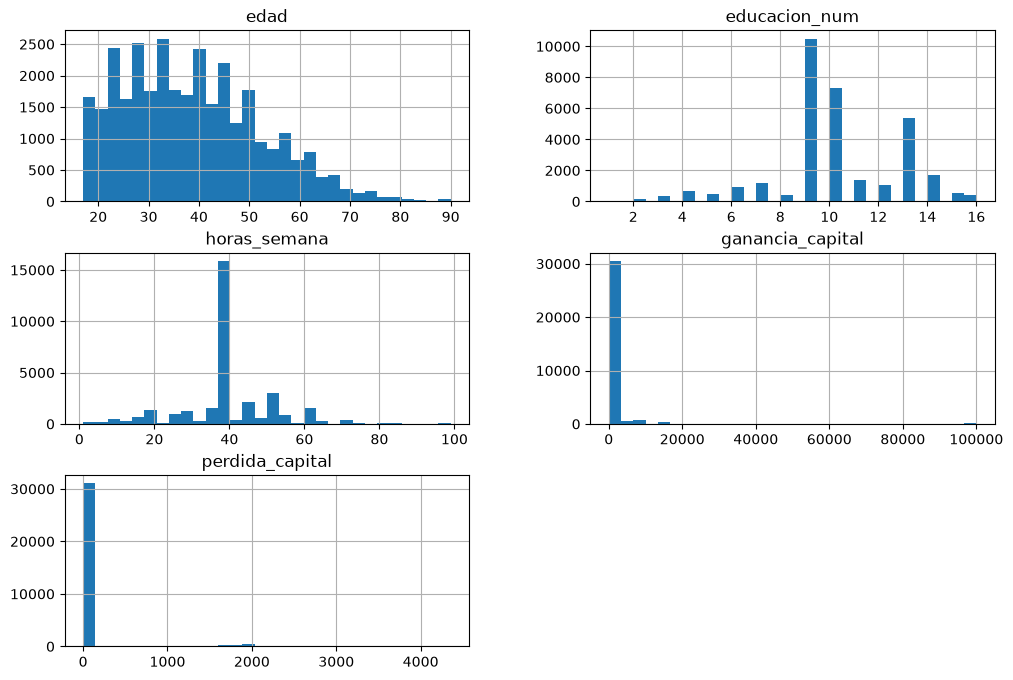

In [22]:
df[numericas].hist(bins=30, figsize=(12, 8))
plt.show()

- `edad`: hay más gente joven que mayor.
- `educacion_num`: hay picos en 9 (bachillerato), 10 (universidad sin terminar) y 13 (grado).
- `horas_semana`: casi todo el mundo está en 40.
- `ganancia_capital` y `perdida_capital`: una barra enorme en el 0 y casi nada más. Más del 90 % de la gente tiene 0.

Ahora comparamos a los que ganan más y menos de 50K:

In [23]:
df.groupby('ingresos')[numericas].mean()

,edad,educacion_num,horas_semana,ganancia_capital,perdida_capital
ingresos,,,,,
0,36.783738,9.595065,38.840210,148.752468,53.142921
1,44.249841,11.611657,45.473026,4006.142456,195.001530


- Los que ganan más de 50K tienen más edad: 44 años de media frente a 37.
- Tienen más estudios: 11,6 frente a 9,6.
- Trabajan más horas: 45 a la semana frente a 39.
- Tienen muchas más ganancias de capital (4.006 frente a 149 de media) y algo más de pérdidas (195 frente a 53).

## 7. Valores atípicos

Los atípicos los buscamos con boxplots:

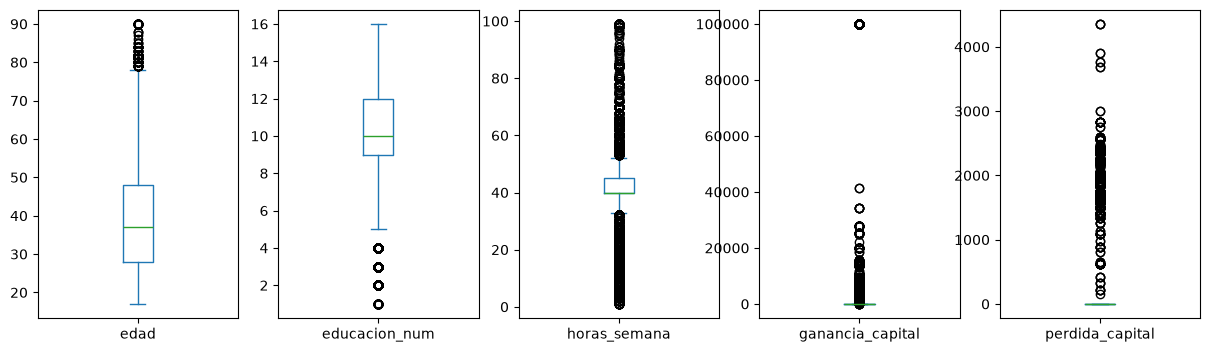

In [24]:
df[numericas].plot(kind='box', subplots=True, figsize=(15, 4))
plt.show()

Salen puntos fuera en casi todas las variables. Antes de borrar nada, miramos si esos valores son errores o son reales:

In [25]:
print('Ganancia de 99.999:', (df['ganancia_capital'] == 99999).sum(), 'personas')
print('Edad de 90:', (df['edad'] == 90).sum(), 'personas')
print('80 horas o más:', (df['horas_semana'] >= 80).sum(), 'personas')

Ganancia de 99.999: 159 personas
Edad de 90: 43 personas
80 horas o más: 341 personas


- 99.999 de ganancias: 159 personas tienen justo esa cifra. Es un tope que puso el censo para no dar cantidades exactas. Todas ellas ganan más de 50K, así que es información real y muy útil.
- 90 años: 43 personas. También es un tope (si tienes más de 90, pone 90). Es una edad posible.
- 80 horas o más: 341 personas. Es mucho, pero puede ser gente con dos trabajos o autónomos.

Ninguno es un error, así que no borramos nada.

Eso sí, `ganancia_capital` y `perdida_capital` tienen valores enormes que pueden despistar a algunos modelos. Lo tendremos en cuenta al preparar los datos para el modelo, por ejemplo aplicando un logaritmo.

## 8. Variables categóricas
Para cada variable miramos qué porcentaje de gente gana más de 50K en cada categoría (dejamos `pais_origen` para después porque tiene 41 países).

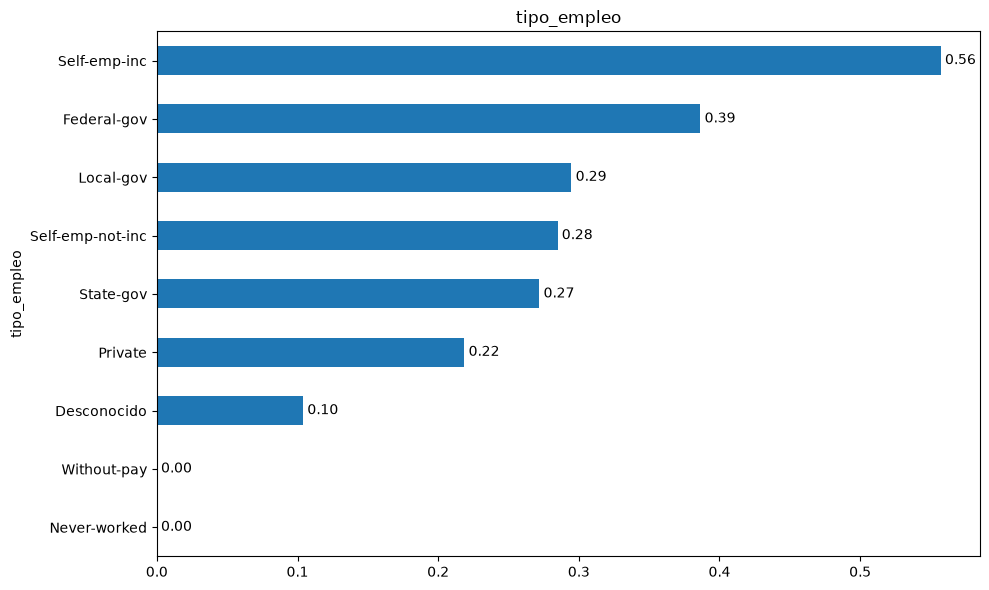

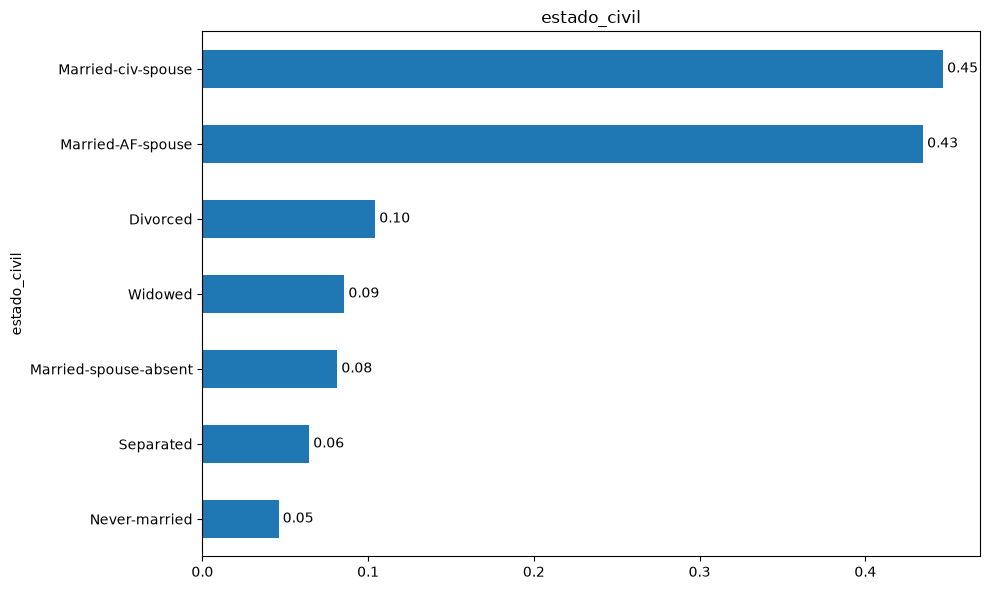

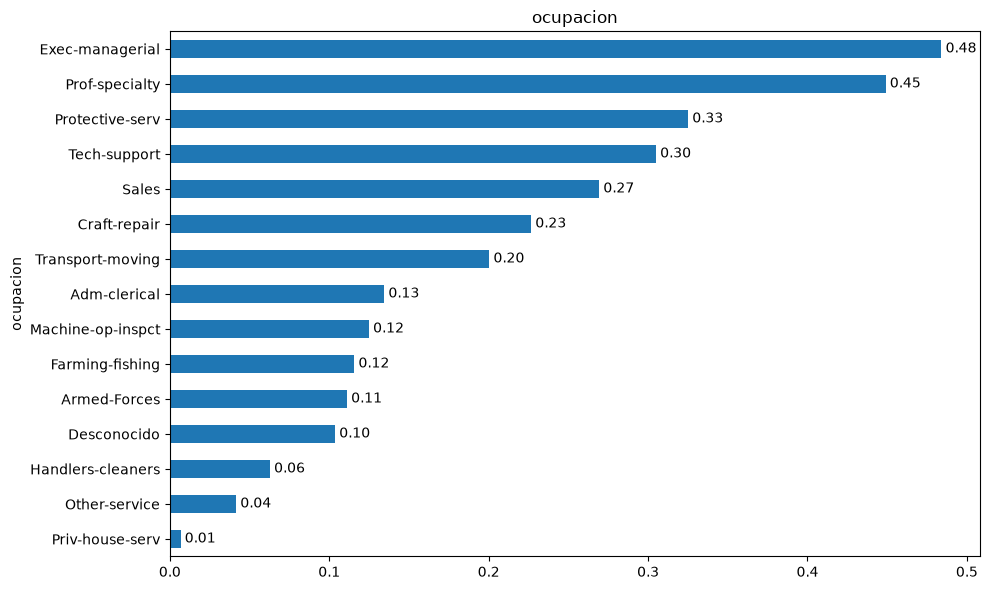

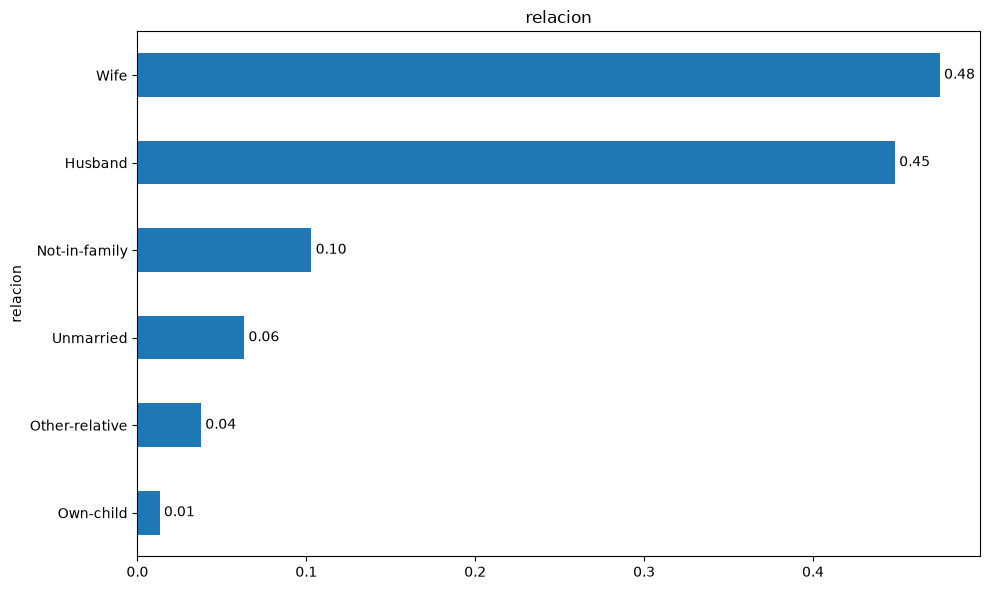

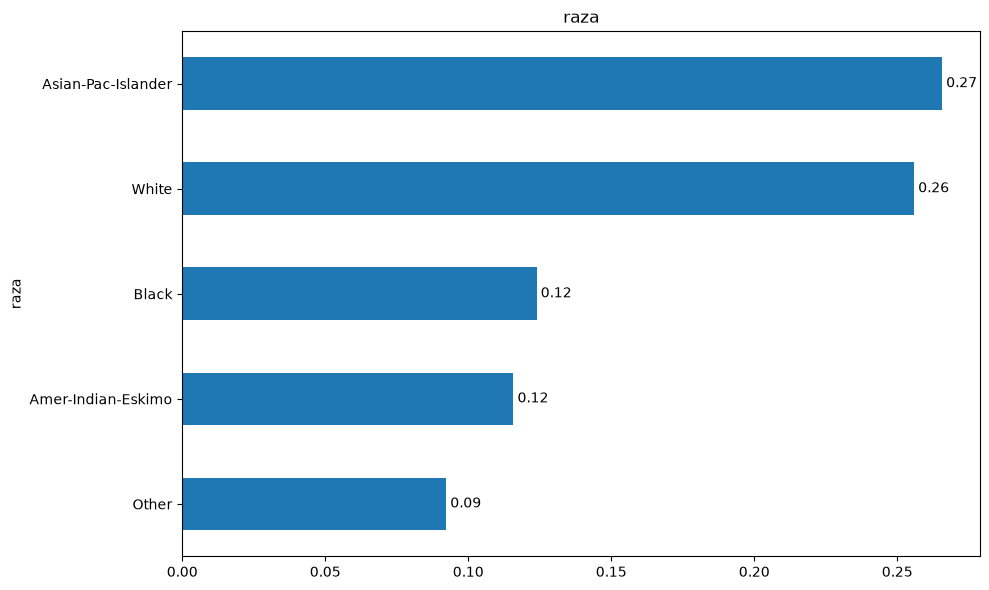

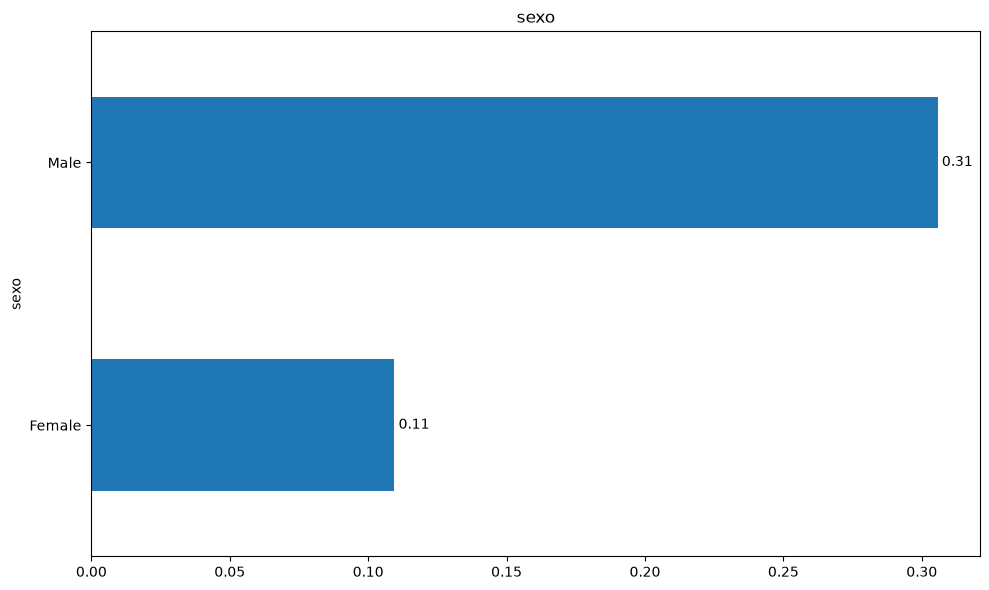

In [26]:
for col in ['tipo_empleo', 'estado_civil', 'ocupacion', 'relacion', 'raza', 'sexo']:
    ax = df.groupby(col)['ingresos'].mean().sort_values().plot(kind='barh', title=col, figsize=(10, 6))
    ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
    plt.tight_layout()
    plt.show()

- **Estado civil y relación:** marcan mucha diferencia. Los casados (`Married-civ-spouse`) ganan más de 50K en un 45 % y los que nunca se han casado solo en un 5 %. En relación pasa lo mismo: maridos y esposas rondan el 45-48 %, y los hijos que viven en casa (`Own-child`) apenas un 1 %.
- **Ocupación:** también diferencia mucho. Los directivos (`Exec-managerial`) y profesionales (`Prof-specialty`) rondan el 45-48 %, mientras que el servicio doméstico (`Priv-house-serv`) casi nunca llega (1 %).
- **Tipo de empleo:** los autónomos con empresa (`Self-emp-inc`) son los que más ganan (56 %). Los de tipo de empleo `Desconocido` se quedan en un 10 %, igual que vimos con la ocupación.
- **Sexo:** los hombres ganan más de 50K un 31 % y las mujeres un 11 %.
- **Raza:** los grupos asiático (27 %) y blanco (26 %) superan al resto, que se queda entre el 9 % y el 12 %.

Sexo y raza son variables delicadas. Las diferencias reflejan desigualdades reales de 1994, y el modelo podría aprenderlas y repetirlas. Lo tendremos en cuenta al evaluar el modelo.

Ahora miramos los países:

In [27]:
df['pais_origen'].value_counts(normalize=True).head()

pais_origen
United-States    0.895857
Mexico           0.019748
Desconocido      0.017905
Philippines      0.006081
Germany          0.004207
Name: proportion, dtype: float64

Casi el 90 % de la gente es de Estados Unidos y el resto se reparte entre 40 países, muchos con muy poca gente. Los agrupamos en dos: `United-States` y `Otro`.

In [28]:
df.loc[df['pais_origen'] != 'United-States', 'pais_origen'] = 'Otro'
df['pais_origen'].value_counts()

pais_origen
United-States    29170
Otro              3391
Name: count, dtype: int64

Ahora `pais_origen` solo tiene dos categorías: unas 29.000 personas de Estados Unidos y unas 3.400 de otros países. Así el modelo no tiene que lidiar con 40 países que casi no tienen gente.

## 9. Correlaciones
Miramos la correlación entre las variables numéricas y con `ingresos`:

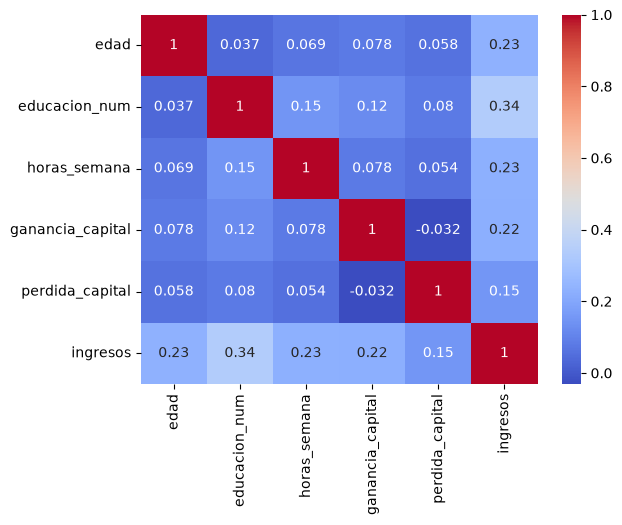

In [29]:
sns.heatmap(df[numericas + ['ingresos']].corr(), annot=True, cmap='coolwarm')
plt.show()

Fijándonos en la fila de `ingresos`:
- La que más se relaciona es `educacion_num` (0,34): a más estudios, más probabilidad de ganar más de 50K.
- Después van `edad`, `horas_semana` y `ganancia_capital` (unos 0,22-0,23).
- `perdida_capital` es la que menos (0,15).

Ninguna pasa de 0,35, así que ninguna variable sola basta para predecir los ingresos. Entre ellas, las correlaciones son todas muy bajas (menos de 0,15), así que no hay variables que digan lo mismo.

## 10. Conclusiones
- **Variable objetivo:** solo un 24 % gana más de 50K. Las clases están desbalanceadas, así que no nos fiaremos solo de la accuracy y separaremos train y test de forma estratificada.
- **Columnas eliminadas:** `educacion`, porque dice lo mismo que `educacion_num`, y `peso_censo`, porque es un dato del censo y no de la persona.
- **Duplicados:** no los borramos. Son personas distintas con el mismo perfil.
- **Nulos:** en `tipo_empleo`, `ocupacion` y `pais_origen` los rellenamos con `Desconocido`, porque la gente sin ocupación apuntada gana menos y queríamos mantener esa información.
- **Valores erróneos:** no hay números imposibles. Algunos países están mal escritos, pero desaparecen al agruparlos en `Otro`.
- **Atípicos:** no borramos ninguno porque todos son valores reales. Las ganancias y pérdidas de capital tienen valores muy grandes, y al preparar el modelo lo tendremos en cuenta, por ejemplo con un logaritmo.
- **Países:** los agrupamos en `United-States` y `Otro`.
- **Variables más útiles:** estado civil, relación, ocupación, estudios, edad, horas trabajadas y ganancias de capital.
- **Cuidado con sexo y raza:** muestran diferencias grandes y el modelo podría aprender esas desigualdades.